# Employee churn - confusion matrices for all models

Compares the **old model** (random forest + lottery) with the **current model** (logistic regression + lottery) on the original data.

Both models get the same data, the same 80/20 split, the same blank-filling and the same lottery (random undersampling of stayers in the training set). `employee_id` is not used as an input.

**How to read a confusion matrix:** rows = what really happened, columns = what the model predicted.
- **TP** - leavers the model flagged (good) &nbsp; **TN** - stayers left alone (good)
- **FP** - stayers wrongly flagged = *false alarms* &nbsp; **FN** - leavers the model missed

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, roc_auc_score, roc_curve
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

## 1. Load the data
The cell looks for the CSV in the usual places (this folder, `data/`, `../data/`). Use the original file for real conclusions.

In [2]:
NAME = "employee_churn_ecommerce_retail_5000_10cols.csv"
candidates = [Path(NAME), Path("data") / NAME, Path("..") / "data" / NAME, Path("..") / NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, f"Could not find {NAME}. Put it next to this notebook or in a data/ folder."

df = pd.read_csv(DATA_PATH)
y = df["termination_date"].notna().astype(int)        # blank termination date = still employed
X = df.drop(columns=["termination_date", "employee_id"])
print(f"File: {DATA_PATH}")
print(f"Employees: {len(df)} | leavers: {y.sum()} | churn rate: {y.mean():.1%}")

File: employee_churn_ecommerce_retail_5000_10cols.csv
Employees: 5000 | leavers: 613 | churn rate: 12.3%


## 2. Split the data and build the shared pipeline
The test set is locked away until evaluation. Blanks are filled with the median (numbers) or most frequent value (categories), learned from the training data only.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

num = X_train.select_dtypes(include="number").columns.tolist()
cat = X_train.select_dtypes(exclude="number").columns.tolist()
P, N = int(y_test.sum()), int((y_test == 0).sum())
print(f"Test set: {len(y_test)} employees = {P} leavers + {N} stayers")

def make_pipeline(classifier):
    pre = ColumnTransformer([
        ("numeric", SklearnPipeline([("imputer", SimpleImputer(strategy="median")),
                                     ("scaler", StandardScaler())]), num),
        ("categorical", SklearnPipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                         ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("preprocessor", pre),
                     ("lottery", RandomUnderSampler(sampling_strategy=0.45, random_state=42)),  # the lottery
                     ("classifier", classifier)])

def pick_threshold(model, spec):
    """spec = a number (fixed cut-off) or ("recall", 0.60) to pick the cut-off from a recall target."""
    if not isinstance(spec, tuple):
        return float(spec)
    oof = cross_val_predict(model, X_train, y_train,
                            cv=StratifiedKFold(5, shuffle=True, random_state=42),
                            method="predict_proba")[:, 1]          # honest scores, training data only
    pos = np.sort(oof[y_train.values == 1])
    return float(pos[int(np.floor((1 - spec[1]) * len(pos)))])

Test set: 1000 employees = 123 leavers + 877 stayers


## 3. Define the models
Add a model by adding one line to this list. The threshold is either a fixed number or `("recall", target)`.

In [4]:
MODELS = [
    ("Old: Random forest + lottery",           RandomForestClassifier(n_estimators=200, random_state=42), 0.45),
    ("Current: Logistic regression + lottery", LogisticRegression(max_iter=1000),                          ("recall", 0.60)),
    # ("Logistic @ 80% recall", LogisticRegression(max_iter=1000), ("recall", 0.80)),
]

## 4. Train every model and score it on the untouched test set

In [5]:
rows, scores = [], {}
for name, clf, spec in MODELS:
    model = make_pipeline(clf)
    thr = pick_threshold(model, spec)
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    scores[name] = p
    rows.append({"Model": name, "Threshold": round(thr, 3), "TP": tp, "FP (false alarms)": fp, "FN (missed)": fn, "TN": tn,
                 "Recall": tp / (tp + fn), "Precision": tp / max(tp + fp, 1),
                 "Balanced acc.": balanced_accuracy_score(y_test, pred), "ROC AUC": roc_auc_score(y_test, p)})

results = pd.DataFrame(rows).set_index("Model")
results.style.format({"Recall": "{:.1%}", "Precision": "{:.1%}", "Balanced acc.": "{:.3f}", "ROC AUC": "{:.3f}"})

,Threshold,TP,FP (false alarms),FN (missed),TN,Recall,Precision,Balanced acc.,ROC AUC
Model,,,,,,,,,
Old: Random forest + lottery,0.450000,54,163,69,714,43.9%,24.9%,0.627,0.699
Current: Logistic regression + lottery,0.353000,77,251,46,626,62.6%,23.5%,0.670,0.738


## 5. Confusion matrices - all models side by side
Percentages are the share of each *actual* group (each row adds to 100%). A dark diagonal means the model gets that group right.

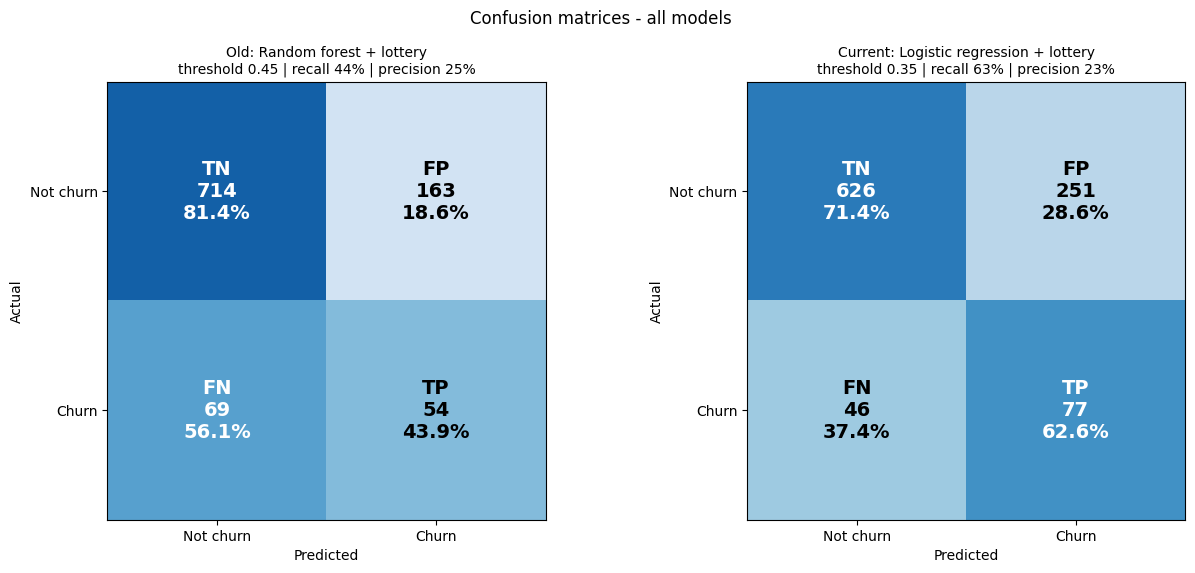

In [6]:
def draw_matrix(ax, tn, fp, fn, tp, title):
    cm = np.array([[tn, fp], [fn, tp]])
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    names = [["TN", "FP"], ["FN", "TP"]]
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i][j]}\n{cm[i, j]}\n{row_pct[i, j]:.1%}", ha="center", va="center",
                    color="white" if row_pct[i, j] > 0.5 else "black", fontsize=14, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Not churn", "Churn"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Not churn", "Churn"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, len(results), figsize=(6.5 * len(results), 5.8), squeeze=False)
for ax, (name, r) in zip(axes[0], results.iterrows()):
    draw_matrix(ax, int(r["TN"]), int(r["FP (false alarms)"]), int(r["FN (missed)"]), int(r["TP"]),
                f"{name}\nthreshold {r['Threshold']:.2f} | recall {r['Recall']:.0%} | precision {r['Precision']:.0%}")
fig.suptitle("Confusion matrices - all models", fontsize=12)
fig.tight_layout()
# fig.savefig("confusion_matrices_all_models.png", dpi=150)   # uncomment to save the picture
plt.show()

## 6. ROC curves - ranking quality, independent of the threshold
The higher curve ranks leavers above stayers more reliably. The dots mark each model's chosen threshold.

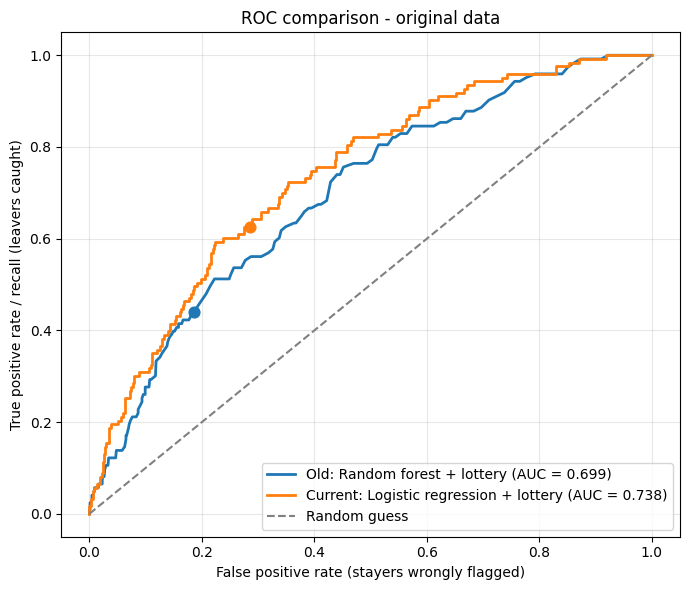

In [7]:
plt.figure(figsize=(7, 6))
for name, p in scores.items():
    f, t, _ = roc_curve(y_test, p)
    plt.plot(f, t, linewidth=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    r = results.loc[name]
    plt.scatter([r["FP (false alarms)"] / (r["FP (false alarms)"] + r["TN"])],
                [r["TP"] / (r["TP"] + r["FN (missed)"])], zorder=5, s=60)
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False positive rate (stayers wrongly flagged)")
plt.ylabel("True positive rate / recall (leavers caught)")
plt.title("ROC comparison - original data")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 7. Reading the result

- The two models sit at **different recall levels** (the old one catches fewer leavers), so compare false alarms only at the *same* recall - the ROC curve does this: the current model's curve is higher, meaning fewer false alarms for the same number of leavers caught.
- Precision stays low for both models on the original data (about a quarter of flags are real leavers, against 12.3% if flagging at random), because the signal in the columns is moderate.
- To compare at a different catch rate, change the threshold spec in section 3, for example `("recall", 0.80)`.